<a href="https://colab.research.google.com/github/Adi2618/AIML/blob/main/AIML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Yrzxiong/Bitcoin-Dataset/master/bitcoin_dataset.csv"
df = pd.read_csv(url)

In [ ]:
# Data Preprocessing for Linear Regression

# 1. Handle Missing Values: For simplicity, we'll fill missing numerical values with the mean.
#    For regression, it's crucial to have numerical data and no NaNs in the features or target.
df_numeric = df.select_dtypes(include=np.number)
for col in df_numeric.columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mean())

# 2. Select relevant columns for our example.
#    We'll predict 'btc_market_price'.
#    For simple linear regression, we'll use 'btc_total_bitcoins' as a predictor.
#    For multiple linear regression, we'll use 'btc_total_bitcoins', 'btc_market_cap', 'btc_trade_volume'.

print("DataFrame after handling NaNs for numerical columns:")
print(df.head())
print("\nMissing values after processing:")
print(df.isnull().sum().loc[lambda x: x > 0])

DataFrame after handling NaNs for numerical columns:
             Date  btc_market_price  btc_total_bitcoins  btc_market_cap  \
0  2/17/2010 0:00               0.0           2043200.0             0.0   
1  2/18/2010 0:00               0.0           2054650.0             0.0   
2  2/19/2010 0:00               0.0           2063600.0             0.0   
3  2/20/2010 0:00               0.0           2074700.0             0.0   
4  2/21/2010 0:00               0.0           2085400.0             0.0   

   btc_trade_volume  btc_blocks_size  btc_avg_block_size  \
0               0.0              0.0            0.000235   
1               0.0              0.0            0.000241   
2               0.0              0.0            0.000228   
3               0.0              0.0            0.000218   
4               0.0              0.0            0.000234   

   btc_n_orphaned_blocks  btc_n_transactions_per_block  \
0                      0                           1.0   
1                  

Simple Linear Regression Results:
Coefficient (Slope): 0.00
Intercept: -1679.50
Mean Squared Error (MSE): 3697659.86
R-squared (R2): 0.17


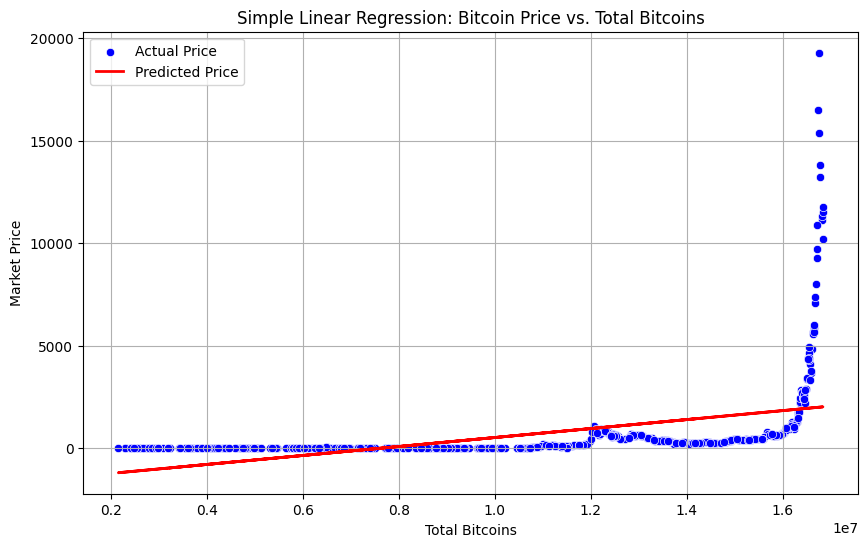

In [ ]:
# Simple Linear Regression Example

# Define the independent variable (X) and dependent variable (y)
X_simple = df[['btc_total_bitcoins']]
y_simple = df['btc_market_price']

# Split the data into training and testing sets
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

# Create a Linear Regression model
model_simple = LinearRegression()

# Train the model
model_simple.fit(X_train_simple, y_train_simple)

# Make predictions on the test set
y_pred_simple = model_simple.predict(X_test_simple)

# Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score

mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print(f"Simple Linear Regression Results:")
print(f"Coefficient (Slope): {model_simple.coef_[0]:.2f}")
print(f"Intercept: {model_simple.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mse_simple:.2f}")
print(f"R-squared (R2): {r2_simple:.2f}")

# Plotting the results
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_test_simple['btc_total_bitcoins'], y=y_test_simple, color='blue', label='Actual Price')
plt.plot(X_test_simple['btc_total_bitcoins'], y_pred_simple, color='red', linewidth=2, label='Predicted Price')
plt.title('Simple Linear Regression: Bitcoin Price vs. Total Bitcoins')
plt.xlabel('Total Bitcoins')
plt.ylabel('Market Price')
plt.legend()
plt.grid(True)
plt.show()

Multiple Linear Regression Results:
Coefficients: [5.07941987e-06 5.93403725e-08 9.09650917e-09]
Intercept: -18.28
Mean Squared Error (MSE): 2150.03
R-squared (R2): 1.00


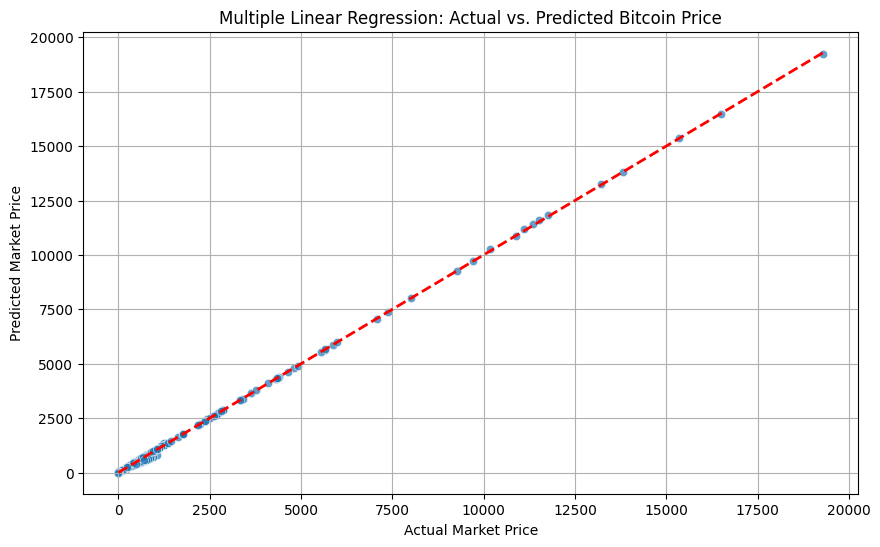

In [ ]:
# Multiple Linear Regression Example

# Define the independent variables (X) and dependent variable (y)
X_multi = df[['btc_total_bitcoins', 'btc_market_cap', 'btc_trade_volume']]
y_multi = df['btc_market_price']

# Split the data into training and testing sets
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

# Create a Linear Regression model
model_multi = LinearRegression()

# Train the model
model_multi.fit(X_train_multi, y_train_multi)

# Make predictions on the test set
y_pred_multi = model_multi.predict(X_test_multi)

# Evaluate the model
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print(f"Multiple Linear Regression Results:")
print(f"Coefficients: {model_multi.coef_}")
print(f"Intercept: {model_multi.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mse_multi:.2f}")
print(f"R-squared (R2): {r2_multi:.2f}")

# To visualize multiple linear regression is harder with 2D plots directly.
# You can plot actual vs. predicted values to get an idea of performance.
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_multi, y=y_pred_multi, alpha=0.7)
plt.plot([y_test_multi.min(), y_test_multi.max()], [y_test_multi.min(), y_test_multi.max()], 'r--', lw=2)
plt.title('Multiple Linear Regression: Actual vs. Predicted Bitcoin Price')
plt.xlabel('Actual Market Price')
plt.ylabel('Predicted Market Price')
plt.grid(True)
plt.show()


In [ ]:
#Uniform Cost Search

import heapq # For priority queue implementation

def dijkstra(graph, start):

    distances = {node: float('infinity') for node in graph}
    distances[start] = 0
    predecessors = {node: None for node in graph}

    # Priority queue to store (distance, node)
    # It will always extract the node with the smallest current distance
    priority_queue = [(0, start)]

    while priority_queue:
        current_distance, current_node = heapq.heappop(priority_queue)

        # If we've already found a shorter path to this node, skip it
        if current_distance > distances[current_node]:
            continue

        for neighbor, weight in graph[current_node].items():
            distance = current_distance + weight

            # If a shorter path to the neighbor is found
            if distance < distances[neighbor]:
                distances[neighbor] = distance
                predecessors[neighbor] = current_node
                heapq.heappush(priority_queue, (distance, neighbor))

    return distances, predecessors

### Example Usage:

In [ ]:
# Define a sample graph
graph = {
    'A': {'B': 1, 'C': 4},
    'B': {'A': 1, 'D': 2, 'E': 5},
    'C': {'A': 4, 'F': 2},
    'D': {'B': 2, 'G': 1},
    'E': {'B': 5, 'G': 3},
    'F': {'C': 2, 'G': 1},
    'G': {'D': 1, 'E': 3, 'F': 1}
}

start_node = 'A'
shortest_distances, path_predecessors = dijkstra(graph, start_node)

print(f"Shortest distances from node {start_node}:")
for node, dist in shortest_distances.items():
    print(f"  To {node}: {dist}")

print("\nPredecessors for reconstructing paths:")
for node, pred in path_predecessors.items():
    print(f"  Node {node}: Predecessor {pred}")

# Function to reconstruct path
def reconstruct_path(predecessors, start, end):
    path = []
    current = end
    while current is not None:
        path.insert(0, current)
        if current == start:
            break
        current = predecessors[current]
    return path if path[0] == start else [] # Return empty if no path or start not found

end_node = 'G'
path_to_g = reconstruct_path(path_predecessors, start_node, end_node)
print(f"\nPath from {start_node} to {end_node}: {path_to_g}")

Shortest distances from node A:
  To A: 0
  To B: 1
  To C: 4
  To D: 3
  To E: 6
  To F: 5
  To G: 4

Predecessors for reconstructing paths:
  Node A: Predecessor None
  Node B: Predecessor A
  Node C: Predecessor A
  Node D: Predecessor B
  Node E: Predecessor B
  Node F: Predecessor G
  Node G: Predecessor D

Path from A to G: ['A', 'B', 'D', 'G']


In [ ]:
#A* algorithm

import heapq

def a_star(graph, start, goal, heuristic):
    # g_score is the cost from start to current node
    g_score = {node: float('inf') for node in graph}
    g_score[start] = 0

    # f_score is g_score + heuristic estimate from current node to goal
    f_score = {node: float('inf') for node in graph}
    f_score[start] = heuristic(start, goal)

    # Priority queue: (f_score, node)
    open_set = [(f_score[start], start)]

    # Dictionary to reconstruct the path
    came_from = {node: None for node in graph}

    while open_set:
        current_f, current_node = heapq.heappop(open_set)

        if current_node == goal:
            return reconstruct_path(came_from, start, goal), g_score[goal]

        # If we've found a better path to this node already, skip it
        if current_f > f_score[current_node]:
            continue

        for neighbor, weight in graph[current_node].items():
            # tentative_g_score is the distance from start to neighbor through current
            tentative_g_score = g_score[current_node] + weight

            if tentative_g_score < g_score[neighbor]:
                came_from[neighbor] = current_node
                g_score[neighbor] = tentative_g_score
                f_score[neighbor] = g_score[neighbor] + heuristic(neighbor, goal)
                heapq.heappush(open_set, (f_score[neighbor], neighbor))

    return None, float('inf') # No path found


### Example Usage:

In [ ]:
# Define a sample graph (same as Dijkstra's example for comparison)
graph_a_star = {
    'A': {'B': 1, 'C': 4},
    'B': {'A': 1, 'D': 2, 'E': 5},
    'C': {'A': 4, 'F': 2},
    'D': {'B': 2, 'G': 1},
    'E': {'B': 5, 'G': 3},
    'F': {'C': 2, 'G': 1},
    'G': {'D': 1, 'E': 3, 'F': 1}
}

# For A*, we need coordinates for a heuristic function (e.g., Euclidean distance)
# Let's assume some arbitrary coordinates for the nodes in a 2D plane
coordinates = {
    'A': (0, 0),
    'B': (1, 0),
    'C': (0, 3),
    'D': (3, 0),
    'E': (2, 4),
    'F': (3, 3),
    'G': (4, 1)
}

# A simple Euclidean distance heuristic function
def euclidean_heuristic(node, goal):
    x1, y1 = coordinates[node]
    x2, y2 = coordinates[goal]
    return ((x1 - x2)**2 + (y1 - y2)**2)**0.5

start_node_a_star = 'A'
goal_node_a_star = 'G'

# Reuse the reconstruct_path function from the Dijkstra's example
# def reconstruct_path(predecessors, start, end): ... (defined in 44402f94)

path_a_star, cost_a_star = a_star(graph_a_star, start_node_a_star, goal_node_a_star, euclidean_heuristic)

print(f"A* Search from {start_node_a_star} to {goal_node_a_star}:")
if path_a_star:
    print(f"  Shortest Path: {path_a_star}")
    print(f"  Total Cost: {cost_a_star}")
else:
    print("  No path found.")
